# 01 — Signal domains, MIMO fading, and independent noise

**Purpose.** Exercise the signal-application layer: correlated flat MIMO,
time-domain convolution, OFDM multiplication, explicit normalization, and AWGN.
The same sampled realization is reused rather than resampled for each operation.

In [5]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython import get_ipython

get_ipython().run_line_magic("matplotlib", "inline")


def find_repo_root(start: Path | None = None) -> Path:
    start = Path.cwd() if start is None else start
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "configs").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from a Channel Dataset repository checkout")


def as_numpy(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)


ROOT = find_repo_root()
SOURCE_DIRECTORY = str(ROOT / "src")
if SOURCE_DIRECTORY not in sys.path:
    sys.path.insert(0, SOURCE_DIRECTORY)

from channel_dataset.core import ExecutionContext

execution = ExecutionContext("torch", "double", "cpu")
backend = execution.array_backend
print(f"Repository: {ROOT.name} | backend={execution.backend} | precision={execution.precision}")

Repository: Channel_Dataset | backend=torch | precision=double


## 1. Correlated flat MIMO and `apply_flat`

In [6]:
from channel_dataset.channels.wireless import ChannelSamplingRequest
from channel_dataset.channels.wireless.fading import register_flat_mimo_model
from channel_dataset.channels.wireless.operators import apply_flat
from channel_dataset.config import load_config
from channel_dataset.registry import ModelRegistry

flat_envelope = load_config(ROOT / "configs/wireless/flat_mimo_fading.yaml")
flat_registry = ModelRegistry()
register_flat_mimo_model(flat_registry)
flat_model = flat_registry.create(flat_envelope)
flat_request = ChannelSamplingRequest(
    256, 1, 1.0, execution, execution.random_stream(1101), "flat-mimo"
)
flat = flat_model.realize(flat_request)
transmitted = backend.ones((256, 1, 2, 32), dtype=execution.complex_dtype)
received = apply_flat(flat, transmitted)

assert flat.shape == (256, 1, 2, 1, 2)
assert tuple(received.shape) == (256, 1, 2, 32)
assert torch.isfinite(received).all()
empirical_link_power = torch.mean(torch.sum(torch.abs(flat.coefficients) ** 2, dim=(2, 4)))
print("flat response shape:", flat.shape)
print("mean link Frobenius power:", round(float(empirical_link_power), 3))
print("correlation mode:", flat_model.config.correlation_mode)

flat response shape: (256, 1, 2, 1, 2)
mean link Frobenius power: 1.038
correlation mode: kronecker


## 2. Reuse one CIR in time and frequency

A zero-delay Rayleigh realization makes the equivalence especially transparent:
the one-tap time response and every OFDM tone apply the same coefficient.
Normalization remains an explicit opt-in transform.

In [7]:
from channel_dataset.channels.wireless.fading import (
    RayleighBlockFading,
    RayleighBlockFadingConfig,
)
from channel_dataset.channels.wireless.operators import apply_ofdm, apply_time
from channel_dataset.channels.wireless.transforms import (
    cir_to_ofdm,
    cir_to_time,
    normalize_response,
)

request = ChannelSamplingRequest(1, 16, 1.0, execution, execution.random_stream(1102))
rayleigh = RayleighBlockFading(RayleighBlockFadingConfig(1, 1, 1, 1, 1.0))
cir = rayleigh.realize(request)
time_response = normalize_response(cir_to_time(cir, 1.0, lag_min=0, lag_max=0))
ofdm_response = normalize_response(
    cir_to_ofdm(cir, backend.array([-30_000.0, 0.0, 30_000.0], dtype="float64"))
)
waveform = backend.ones((1, 1, 1, 16), dtype="complex128")
grid = backend.ones((1, 1, 1, 16, 3), dtype="complex128")
time_output = apply_time(time_response, waveform)
ofdm_output = apply_ofdm(ofdm_response, grid)

assert torch.allclose(ofdm_output, time_output[..., None], atol=1e-12, rtol=1e-12)
assert torch.equal(apply_time(time_response, waveform), time_output)
print("time response:", time_response.shape, "lag range:", (time_response.lag_min, time_response.lag_max))
print("OFDM response:", ofdm_response.shape)
print("zero-delay time/OFDM agreement: yes")

time response: (1, 1, 1, 1, 1, 16, 1) lag range: (0, 0)
OFDM response: (1, 1, 1, 1, 1, 16, 3)
zero-delay time/OFDM agreement: yes


## 3. Add AWGN through an independent child stream

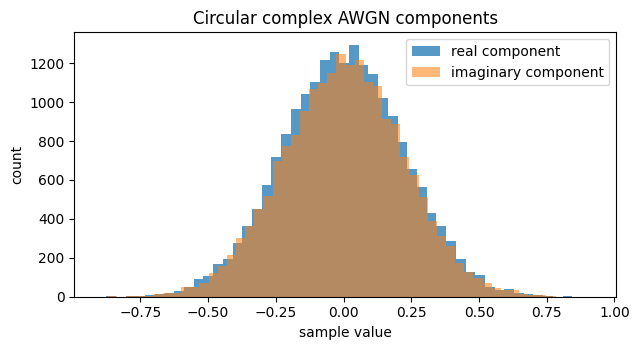

target E[|n|²]: 0.1
measured E[|n|²]: 0.0996


In [8]:
from channel_dataset.channels.wireless.noise import AdditiveWhiteGaussianNoise, AWGNConfig

noise_variance = 0.1
noise_model = AdditiveWhiteGaussianNoise(AWGNConfig(noise_variance))
zeros = backend.zeros((20_000,), dtype="complex128")
noise = noise_model.apply(zeros, execution.random_stream(1103))
replayed_noise = noise_model.apply(zeros, execution.random_stream(1103))
measured_variance = torch.mean(torch.abs(noise) ** 2)

assert torch.equal(noise, replayed_noise)
assert abs(float(measured_variance) - noise_variance) < 0.01

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(as_numpy(noise.real), bins=50, alpha=0.75, label="real component")
ax.hist(as_numpy(noise.imag), bins=50, alpha=0.55, label="imaginary component")
ax.set(title="Circular complex AWGN components", xlabel="sample value", ylabel="count")
ax.legend()
fig.tight_layout()
plt.show()
print("target E[|n|²]:", noise_variance)
print("measured E[|n|²]:", round(float(measured_variance), 4))

## Manual check and next experiments

- Change the flat-MIMO correlation profile and inspect empirical antenna covariance.
- Give the CIR a nonzero delay and expand the time-domain lag window.
- Remove `normalize_response` to see why normalization is never implicit.
- Change the AWGN variance and confirm real/imaginary variances are each half of it.